## 1. Mengimport Library dan Konfigurasi Dasar

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 150

DATA_DIR = Path("dataset/sst_5_wilayah") if Path("dataset/sst_5_wilayah").exists() else Path("../dataset/sst_5_wilayah")
OUTPUT_DIR = Path("reports/figures") if Path("reports").exists() else Path("../reports/figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

WILAYAH = [
    "Pasifik_Nino34",
    "Selat_Makassar",
    "Selat_Karimata",
    "Selatan_Jawa",
    "Maluku_Utara_Papua"
]

print("Path dataset ditemukan:", DATA_DIR.resolve())

Path dataset ditemukan: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\sst_5_wilayah


## 2. Memuat dan Menggabungkan Data NetCDF

In [5]:
data_dict = {}

for region in WILAYAH:
    files = sorted([f for f in DATA_DIR.glob(f"{region}_*.nc") if "2015_2025" not in f.name])
    
    if not files:
        print(f"File untuk {region} tidak ditemukan di {DATA_DIR}")
        continue
        
    ds_list = []
    for f in files:
        with xr.open_dataset(f) as ds:
            da = ds['sst'].load()
            if 'zlev' in da.dims:
                da = da.squeeze('zlev', drop=True)
            ds_list.append(da)
            
    combined = xr.concat(ds_list, dim='time').sortby('time')
    _, idx = np.unique(combined['time'], return_index=True)
    combined = combined.isel(time=idx)
    data_dict[region] = combined
    print(f"Berhasil memuat {region}: {len(combined.time)} timestamps")

Berhasil memuat Pasifik_Nino34: 4001 timestamps
Berhasil memuat Selat_Makassar: 4001 timestamps
Berhasil memuat Selat_Karimata: 4001 timestamps
Berhasil memuat Selatan_Jawa: 4001 timestamps
Berhasil memuat Maluku_Utara_Papua: 4001 timestamps


## 3. Pengecekan Integritas Data & Land Masking

In [6]:
integrity_records = []

for name, da in data_dict.items():
    times = pd.to_datetime(da.time.values)
    total_days = len(times)
    expected_days = len(pd.date_range(times.min(), times.max(), freq='D'))
    missing_days = expected_days - total_days
    
    total_grid = np.prod(da.shape[1:])
    land_pixels = np.isnan(da.values).all(axis=0).sum()
    land_pct = (land_pixels / total_grid) * 100.0
    
    valid_data = da.values[~np.isnan(da.values)]
    outliers = np.sum((valid_data < 10.0) | (valid_data > 38.0))
    
    integrity_records.append({
        "Wilayah": name,
        "Total Hari": total_days,
        "Hari Hilang": missing_days,
        "Grid (Lat x Lon)": f"{da.shape[1]} x {da.shape[2]}",
        "Daratan (%)": round(land_pct, 2),
        "Outlier": int(outliers)
    })

df_integrity = pd.DataFrame(integrity_records)
print(df_integrity.to_string(index=False))

           Wilayah  Total Hari  Hari Hilang Grid (Lat x Lon)  Daratan (%)  Outlier
    Pasifik_Nino34        4001           17         41 x 201         0.00        0
    Selat_Makassar        4001           17          29 x 17        35.90        0
    Selat_Karimata        4001           17          21 x 21        16.33        0
      Selatan_Jawa        4001           17          17 x 41         5.16        0
Maluku_Utara_Papua        4001           17          25 x 61        11.93        0


## 4. Perhitungan Statistik Deskriptif

In [7]:
stats_records = []

for name, da in data_dict.items():
    vals = da.values.flatten()
    vals = vals[~np.isnan(vals)]
    
    stats_records.append({
        "Wilayah": name,
        "Mean": np.mean(vals),
        "Std": np.std(vals),
        "Min": np.min(vals),
        "Q25": np.percentile(vals, 25),
        "Median": np.median(vals),
        "Q75": np.percentile(vals, 75),
        "Max": np.max(vals)
    })

df_stats = pd.DataFrame(stats_records).round(2)
print(df_stats.to_string(index=False))

           Wilayah      Mean  Std       Min       Q25    Median       Q75       Max
    Pasifik_Nino34 27.180000 1.49 19.690001 26.219999 27.320000 28.280001 32.669998
    Selat_Makassar 29.410000 0.60 25.850000 29.049999 29.459999 29.809999 32.130001
    Selat_Karimata 29.280001 0.84 24.840000 28.740000 29.360001 29.889999 33.180000
      Selatan_Jawa 28.129999 1.31 20.730000 27.230000 28.389999 29.100000 31.809999
Maluku_Utara_Papua 29.559999 0.65 25.150000 29.230000 29.660000 30.010000 32.410000


## 5. Ekstraksi Rata-rata Harian & Visualisasi Tren Waktu (2015–2025)


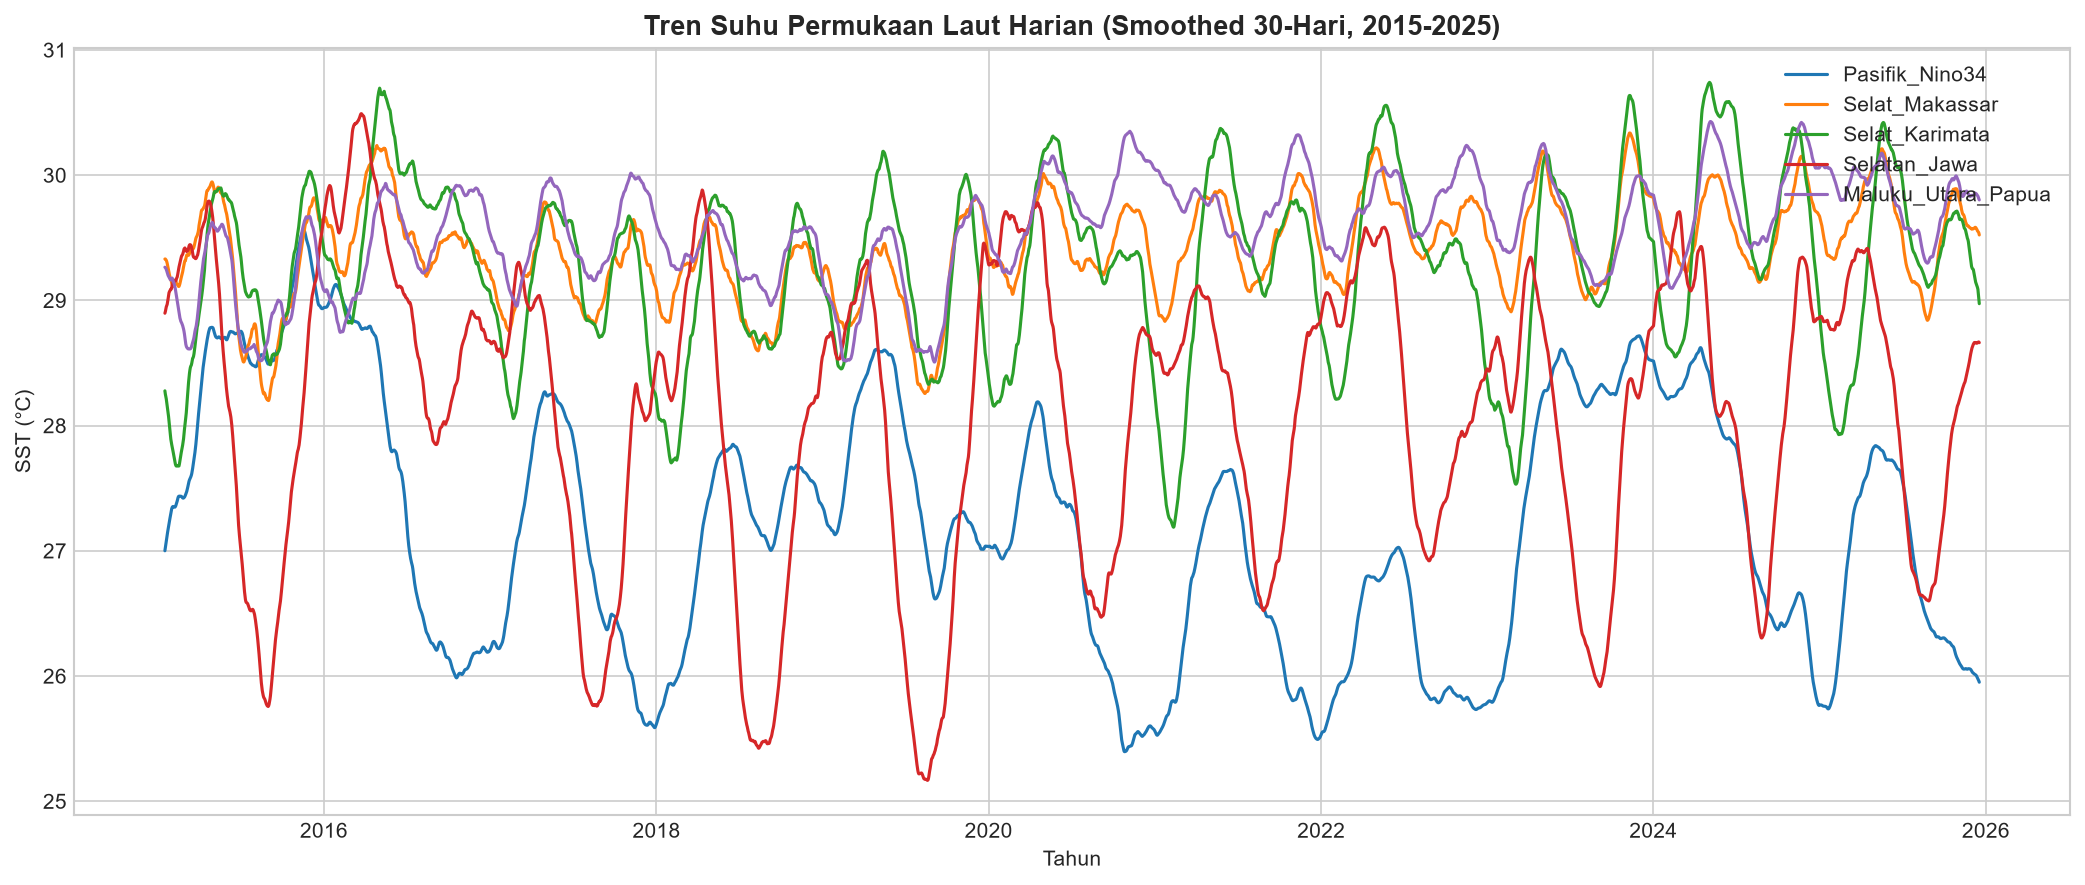

In [8]:
daily_means = {}
for name, da in data_dict.items():
    daily_means[name] = da.mean(dim=['latitude', 'longitude'], skipna=True).to_pandas()

df_daily = pd.DataFrame(daily_means)

plt.figure(figsize=(14, 6))
for col in df_daily.columns:
    plt.plot(df_daily[col].rolling(30, center=True).mean(), label=col, linewidth=1.5)

plt.title("Tren Suhu Permukaan Laut Harian (Smoothed 30-Hari, 2015-2025)", fontsize=13, fontweight='bold')
plt.ylabel("SST (°C)")
plt.xlabel("Tahun")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_timeseries_sst_2015_2025.png")
plt.show()

## 6. Visualisasi Siklus Musiman Bulanan & Fenomena Upwelling

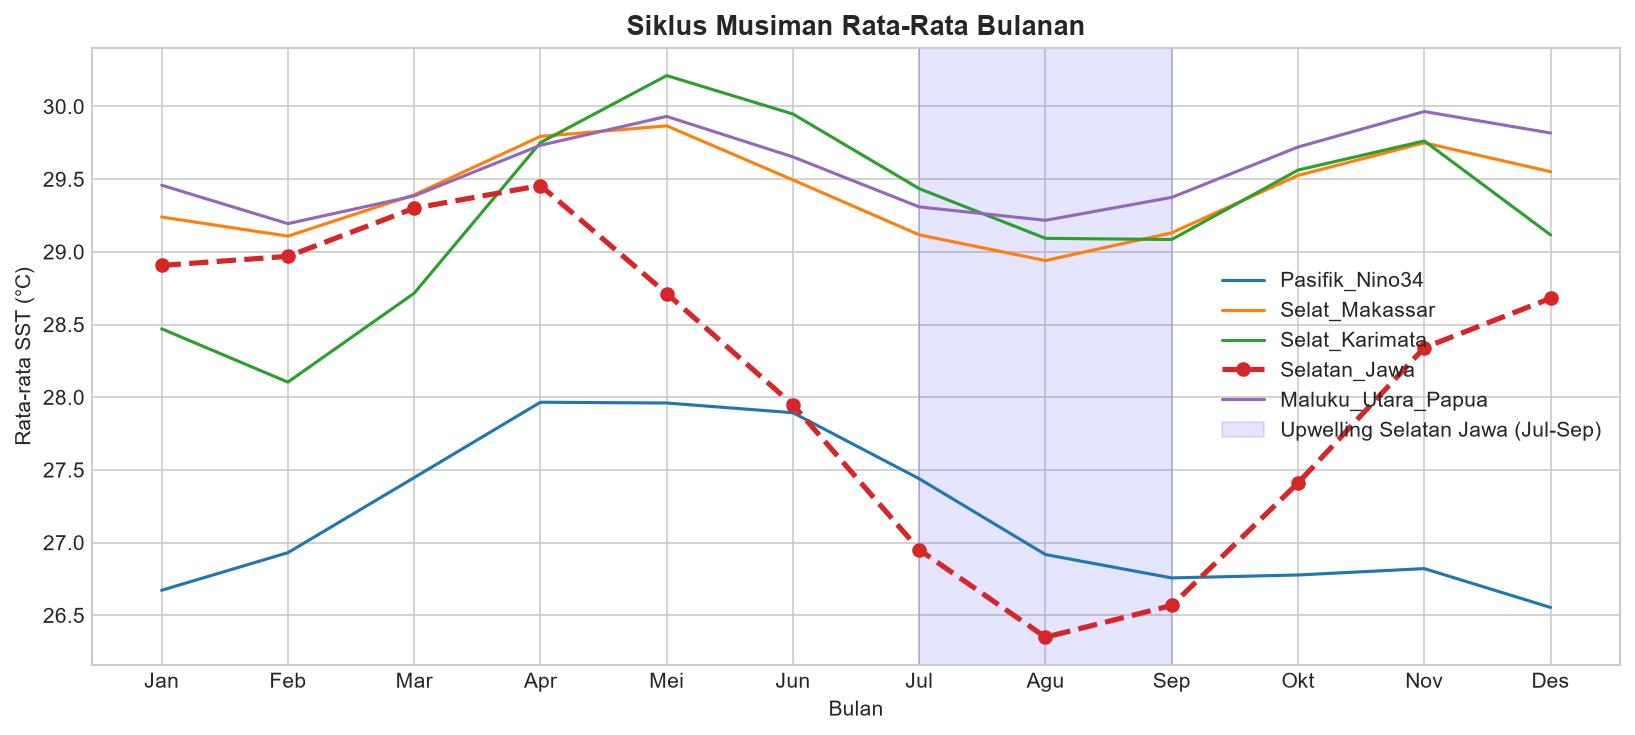

In [9]:
monthly_clim = df_daily.groupby(df_daily.index.month).mean()
months = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

plt.figure(figsize=(11, 5))
for col in monthly_clim.columns:
    lw = 2.5 if col == "Selatan_Jawa" else 1.5
    marker = 'o--' if col == "Selatan_Jawa" else '-'
    plt.plot(range(1, 13), monthly_clim[col], marker, label=col, linewidth=lw)

plt.xticks(range(1, 13), months)
plt.axvspan(7, 9, color='blue', alpha=0.1, label='Upwelling Selatan Jawa (Jul-Sep)')
plt.title("Siklus Musiman Rata-Rata Bulanan", fontsize=13, fontweight='bold')
plt.ylabel("Rata-rata SST (°C)")
plt.xlabel("Bulan")
plt.legend(loc="best")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_monthly_seasonality.png")
plt.show()

## 7. Visualisasi Distribusi Suhu

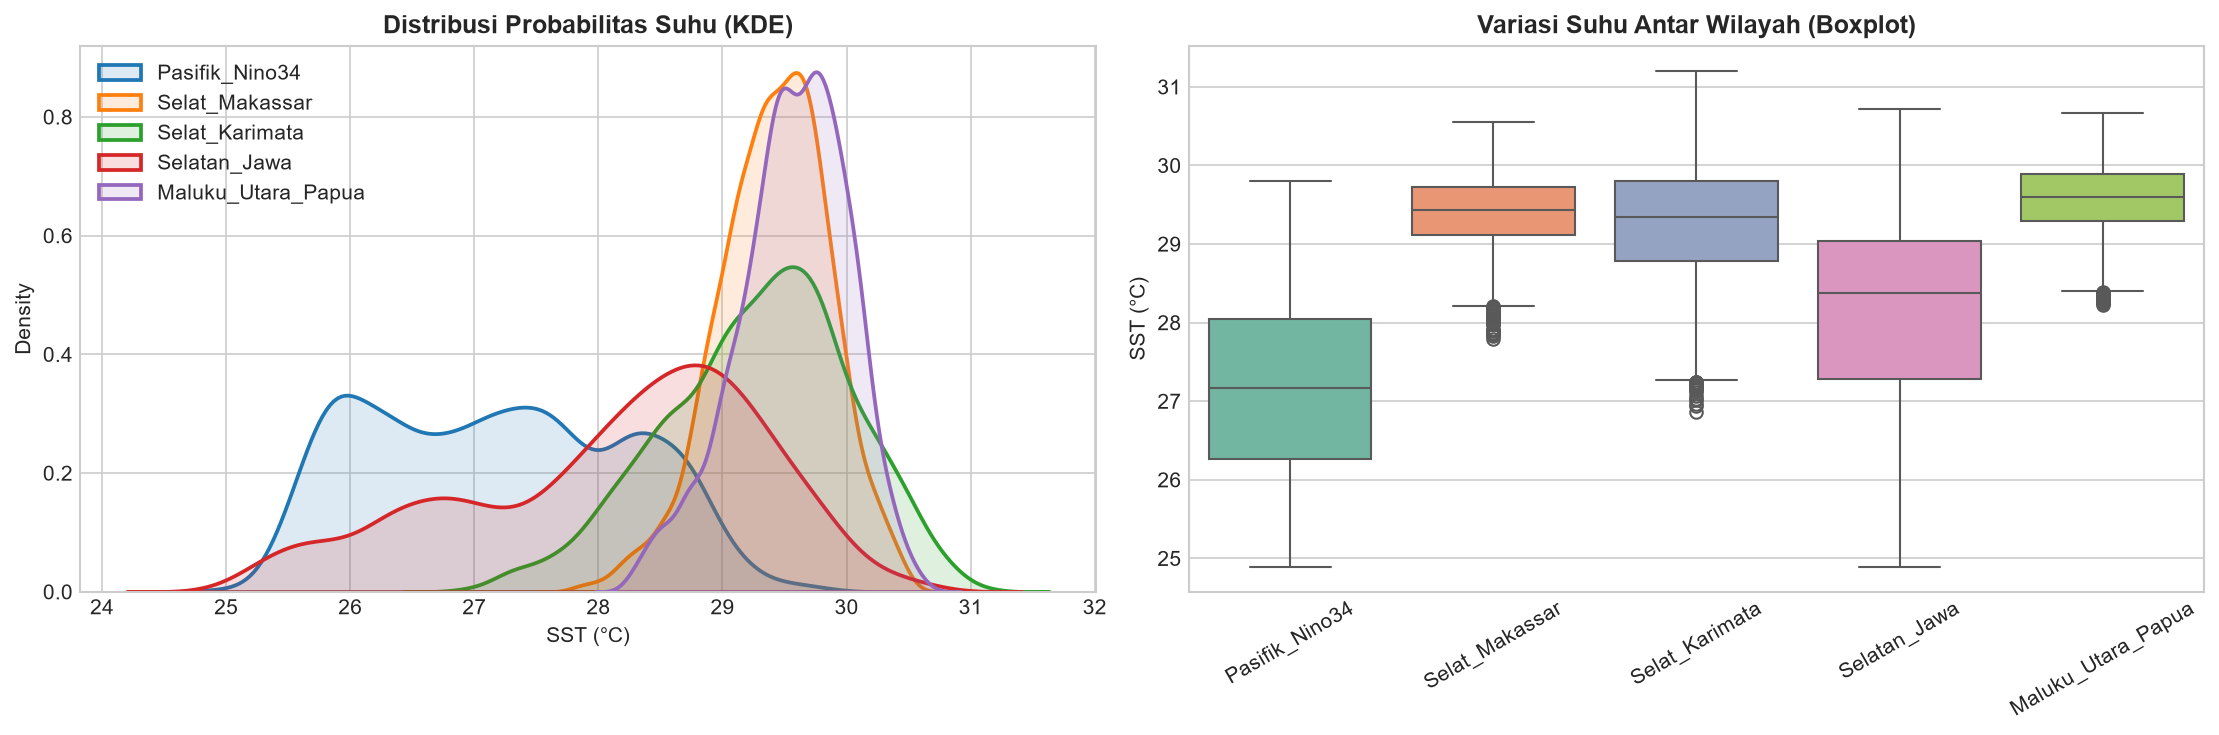

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for col in df_daily.columns:
    sns.kdeplot(df_daily[col].dropna(), ax=axes[0], label=col, fill=True, alpha=0.15, linewidth=1.8)
axes[0].set_title("Distribusi Probabilitas Suhu (KDE)", fontweight='bold')
axes[0].set_xlabel("SST (°C)")
axes[0].set_ylabel("Density")
axes[0].legend(loc="upper left")

sns.boxplot(data=df_daily, ax=axes[1], palette="Set2")
axes[1].set_title("Variasi Suhu Antar Wilayah (Boxplot)", fontweight='bold')
axes[1].set_ylabel("SST (°C)")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_temperature_distributions.png")
plt.show()

## 8. Visualisasi Peta Kontur Spasial 2D Tiap Wilayah

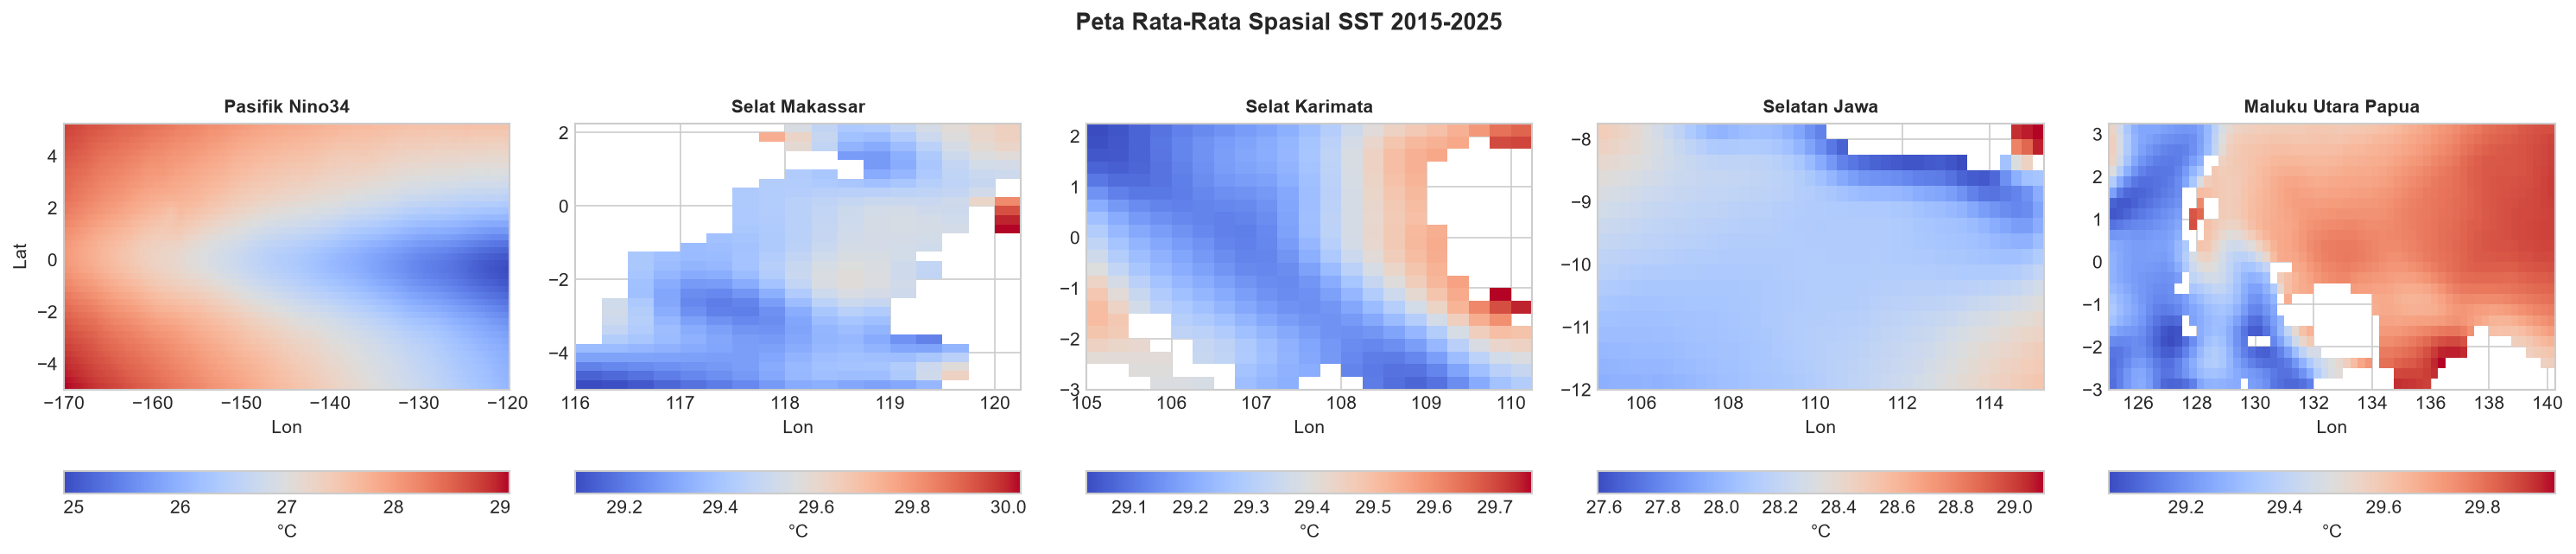

In [11]:
fig, axes = plt.subplots(1, len(data_dict), figsize=(4 * len(data_dict), 4))

for idx, (name, da) in enumerate(data_dict.items()):
    ax = axes[idx]
    spatial_mean = da.mean(dim='time', skipna=True)
    im = ax.pcolormesh(
        spatial_mean.longitude,
        spatial_mean.latitude,
        spatial_mean.values,
        cmap='coolwarm',
        shading='auto'
    )
    ax.set_title(name.replace("_", " "), fontsize=10, fontweight='bold')
    ax.set_xlabel("Lon")
    if idx == 0:
        ax.set_ylabel("Lat")
    plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.2, label='°C')

plt.suptitle("Peta Rata-Rata Spasial SST 2015-2025", fontsize=13, fontweight='bold', y=1.05)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_spatial_mean_grids.png", bbox_inches='tight')
plt.show()

## 9. Analisis Korelasi Wilayah

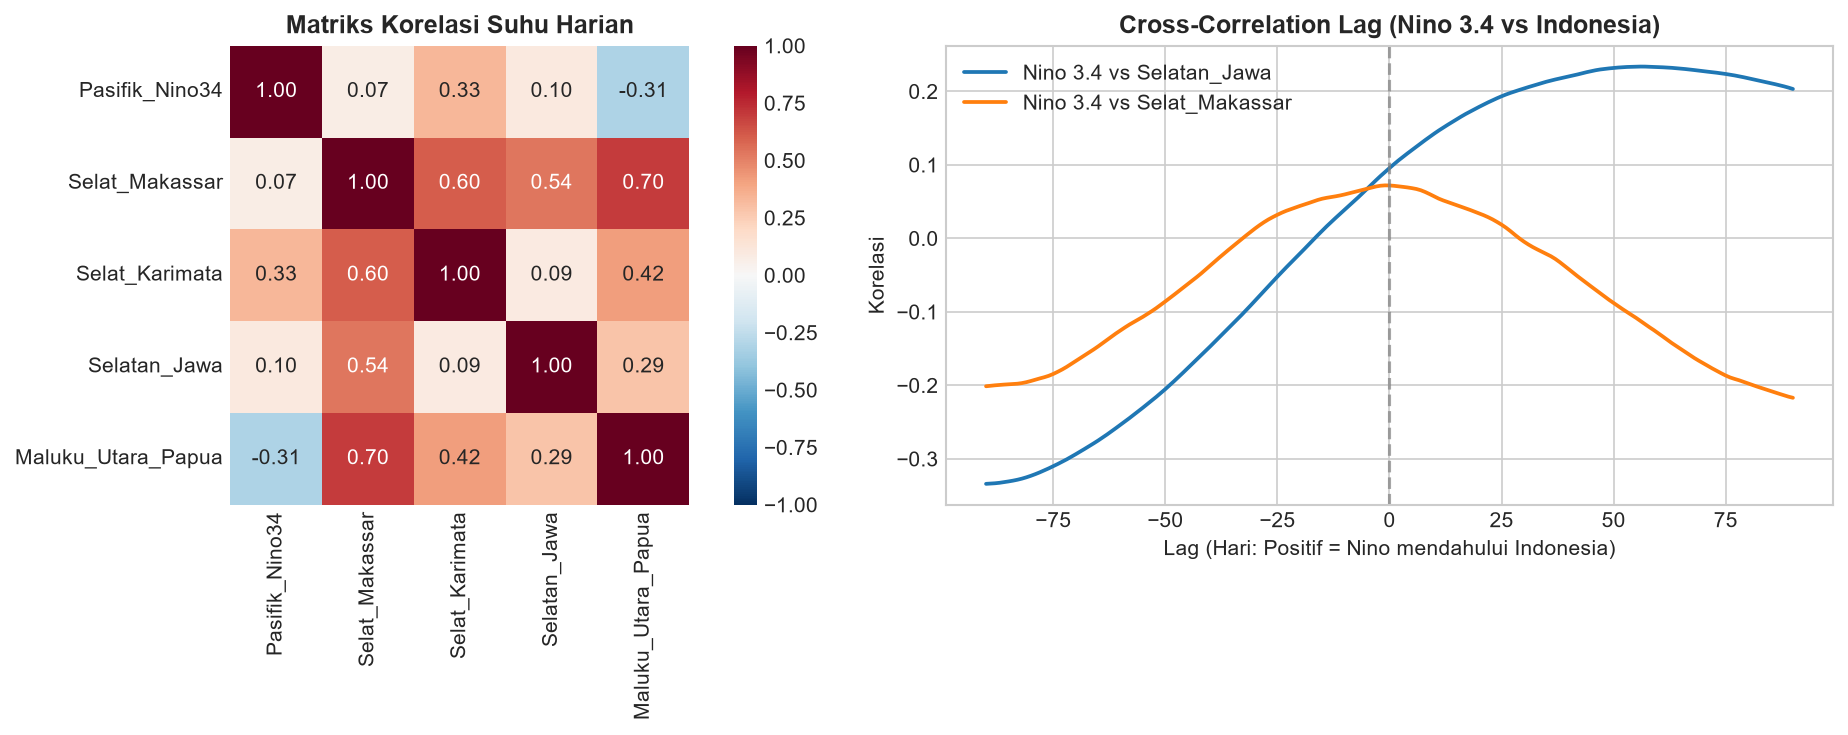

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

corr = df_daily.corr()
sns.heatmap(corr, annot=True, cmap='RdBu_r', vmin=-1, vmax=1, fmt=".2f", ax=axes[0], square=True)
axes[0].set_title("Matriks Korelasi Suhu Harian", fontweight='bold')

nino = df_daily["Pasifik_Nino34"].dropna()
lags = np.arange(-90, 91, 1)

for target in ["Selatan_Jawa", "Selat_Makassar"]:
    target_series = df_daily[target].dropna()
    common_idx = nino.index.intersection(target_series.index)
    
    s1 = nino.loc[common_idx].values
    s2 = target_series.loc[common_idx].values
    
    s1_norm = (s1 - np.mean(s1)) / (np.std(s1) * len(s1))
    s2_norm = (s2 - np.mean(s2)) / np.std(s2)
    
    cc = np.correlate(s1_norm, s2_norm, mode='full')
    mid = len(cc) // 2
    axes[1].plot(lags, cc[mid - 90 : mid + 91], label=f"Nino 3.4 vs {target}", linewidth=1.8)

axes[1].axvline(0, color='gray', linestyle='--', alpha=0.7)
axes[1].set_title("Cross-Correlation Lag (Nino 3.4 vs Indonesia)", fontweight='bold')
axes[1].set_xlabel("Lag (Hari: Positif = Nino mendahului Indonesia)")
axes[1].set_ylabel("Korelasi")
axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_cross_correlations.png")
plt.show()
